# Lab 2.3 — Evaluate RAG retrieval

**Course:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Topic:** 2.3 (links to 4.3)

Reproduces locally what Amazon Bedrock Knowledge Bases and Amazon Bedrock RAG evaluations do:

1. Split a corpus into chunks with two strategies.
2. Measure retrieval with **Recall@k**, **Precision@k**, and **MRR**, without generating answers.
3. See how, without a **metadata filter**, a question retrieves another tenant's data.
4. Separate retrieval failures from generation failures.

No AWS account, credentials, or external models needed: TF-IDF replaces embeddings and an extractive generator replaces the LLM.

## 0. Setup

The reusable modules live in `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import chunking
import corpus
import evaluation
import plots
from retrieval import Retriever

LANG = "en"
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 70)

## 1. Corpus and labelled questions

Two companies (*tenants*), `andina` and `boreal`, share the same platform. Each has 6 internal policies with the **same structure and different values**: the typical multi-tenant SaaS case.

Each question has an expected answer and its **evidence sentence** in the correct tenant's document. Questions don't name the company, just like a real user.

In [3]:
docs = corpus.documents(LANG)
queries = corpus.queries(LANG)
corpus.export(docs, Path("data/corpus"))
print(f"documents={len(docs)}  tenants={sorted({d['tenant'] for d in docs})}  questions={len(queries)}\n")
print(docs[0]["doc_id"])
print(docs[0]["text"])

documents=12  tenants=['andina', 'boreal']  questions=30

andina/vacation
At Andina Foods, every permanent employee gets 22 business days of paid vacation per calendar year. Days accrue proportionally from the first month of work and are recorded in the human resources portal.

Vacation is requested in the portal at least 15 days in advance. The team lead approves or rejects the request within three business days. Month-end accounting closes may have restrictions.

At year end, a maximum of 5 unused days can be carried over to the next year. Carried-over days expire on March 31. Unused days are not paid out in cash, except when the law requires it at contract end.


In [4]:
pd.DataFrame(queries)[["query_id", "tenant", "question", "answer", "doc_id"]].head(6)

,query_id,tenant,question,answer,doc_id
0,andina-q01,andina,How many days of paid vacation do I get per year?,22 business days,andina/vacation
1,boreal-q01,boreal,How many days of paid vacation do I get per year?,18 business days,boreal/vacation
2,andina-q02,andina,How far in advance must I request vacation?,15 days in advance,andina/vacation
3,boreal-q02,boreal,How far in advance must I request vacation?,30 days in advance,boreal/vacation
4,andina-q03,andina,How many days off I didn't take can I move to next year?,5 unused days,andina/vacation
5,boreal-q03,boreal,How many days off I didn't take can I move to next year?,10 unused days,boreal/vacation


`export` saves each document with a `.metadata.json` file, the format a Bedrock Knowledge Bases S3 data source uses for filterable attributes:

In [5]:
print(Path(f"data/corpus/{docs[0]['doc_id']}.txt.metadata.json").read_text())

{
  "metadataAttributes": {
    "tenant": "andina",
    "topic": "vacation"
  }
}


## 2. Two chunking strategies

- **`fixed-30`**: 30-word windows with no overlap. It cuts sentences and paragraphs.
- **`paragraph`**: one chunk per paragraph. It respects the document's logical boundaries.

A chunk is **relevant** if it overlaps the evidence sentence in the correct document.

In [6]:
chunks = {name: chunking.chunk_corpus(docs, name) for name in chunking.STRATEGIES}
for name, cs in chunks.items():
    words = pd.Series([len(c["text"].split()) for c in cs])
    print(f"{name:<10} chunks={len(cs):>3}  words/chunk: mean={words.mean():.0f}  min={words.min()}  max={words.max()}")

fixed-30   chunks= 38  words/chunk: mean=27  min=13  max=30
paragraph  chunks= 36  words/chunk: mean=29  min=23  max=40


In [7]:
# Una pregunta cuya evidencia queda partida en dos chunks fijos. A question whose evidence is split across two fixed chunks.
q = next(q for q in queries if len(evaluation.relevant_ids(q, chunks["fixed-30"])) > 1)
print(q["query_id"], "|", q["answer"])
for name, cs in chunks.items():
    print(f"\n--- {name}")
    for c in cs:
        if c["chunk_id"] in evaluation.relevant_ids(q, cs):
            print(f"[{c['chunk_id']}] {c['text']!r}")

andina-q05 | within 30 days

--- fixed-30
[andina/expenses#fixed-0] 'At Andina Foods, business travel expenses are reimbursed with a receipt. The meal limit is 40 USD per travel day, tips included. Alcoholic drinks are not reimbursed.\n\nReceipts are uploaded'
[andina/expenses#fixed-1] 'to the expense app within 30 days after the expense. After that deadline, reimbursement requires an exception signed by the finance team.\n\nAny single expense above 500 USD needs prior'

--- paragraph
[andina/expenses#paragraph-1] 'Receipts are uploaded to the expense app within 30 days after the expense. After that deadline, reimbursement requires an exception signed by the finance team.'


With `fixed-30`, the evidence sentence is split across two chunks: neither one contains all of it.

## 3. Evaluate retrieval only

Without generating answers, for each question and each k:

- **Recall@k**: share of the relevant chunks that appear in the top-k.
- **Precision@k**: share of the top-k that is relevant.
- **MRR**: mean of 1/rank of the first relevant chunk.
- **Leak**: the top-k contains another tenant's chunk.

Each strategy is evaluated without a filter and with the filter `tenant = <question's tenant>`.

In [8]:
retrievers = {name: Retriever(cs, LANG) for name, cs in chunks.items()}
summaries = {
    (name, use_filter): evaluation.summary(evaluation.retrieval_metrics(r, queries, use_filter=use_filter))
    for name, r in retrievers.items()
    for use_filter in (False, True)
}
pd.concat({f"{name} | filter={use_filter}": s.loc[[1, 3, 5]] for (name, use_filter), s in summaries.items()})

recall  precision  coverage    mrr   leak
                         k                                           
fixed-30 | filter=False  1   0.333      0.433     0.363  0.433  0.500
                         3   0.733      0.333     0.777  0.650  0.933
                         5   0.867      0.247     0.878  0.657  0.933
fixed-30 | filter=True   1   0.667      0.867     0.727  0.867  0.000
                         3   0.867      0.422     0.862  0.867  0.000
                         5   0.933      0.267     0.929  0.880  0.000
paragraph | filter=False 1   0.400      0.400     0.400  0.400  0.500
                         3   0.833      0.278     0.833  0.611  0.933
                         5   0.900      0.180     0.900  0.628  0.933
paragraph | filter=True  1   0.800      0.800     0.800  0.800  0.000
                         3   0.867      0.289     0.867  0.833  0.000
                         5   0.933      0.187     0.933  0.850  0.000

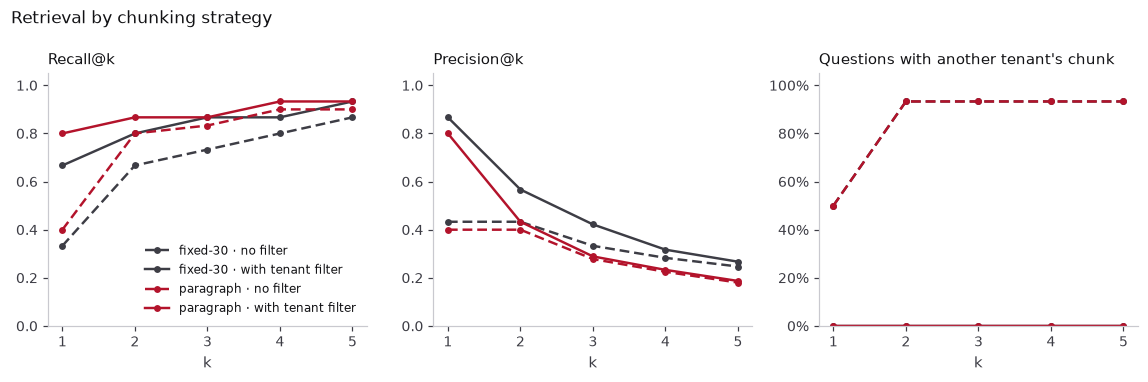

In [9]:
plots.metrics_vs_k(summaries, LANG);

- **Without a filter**, half of the top-1 results come from the other tenant: both documents are nearly identical and only the values change. Recall@1 stays at or below 0.43.
- **With the filter**, `paragraph` wins on Recall@1 because the evidence stays whole in one chunk.
- Precision@k favours `fixed-30` at k ≥ 2 only because the split evidence counts as **two** relevant chunks. To compare chunking strategies, use recall or coverage, not precision alone.

## 4. Per-tenant metadata filter (links to topic 4.3)

The same question, with and without the filter. Both tenants' chunks tie on score, so their order is arbitrary. Without the filter, the other tenant's chunk ranks first: the answer would be **plausible and wrong**, and it exposes someone else's data.

In [10]:
r = retrievers["paragraph"]
q = next(q for q in queries if r.search(q["question"], k=1)[0]["tenant"] != q["tenant"])
print(f"{q['query_id']} | tenant={q['tenant']} | expected: {q['answer']}\n{q['question']}")
for use_filter in (False, True):
    print(f"\nfilter={use_filter}")
    for h in r.search(q["question"], k=3, tenant=q["tenant"] if use_filter else None):
        print(f"  {h['score']:.3f}  {h['chunk_id']:<26} {h['text'][:60]}...")

andina-q01 | tenant=andina | expected: 22 business days
How many days of paid vacation do I get per year?

filter=False
  0.412  boreal/vacation#paragraph-0 At Boreal Health, every permanent employee gets 18 business ...
  0.412  andina/vacation#paragraph-0 At Andina Foods, every permanent employee gets 22 business d...
  0.361  andina/vacation#paragraph-2 At year end, a maximum of 5 unused days can be carried over ...

filter=True
  0.412  andina/vacation#paragraph-0 At Andina Foods, every permanent employee gets 22 business d...
  0.361  andina/vacation#paragraph-2 At year end, a maximum of 5 unused days can be carried over ...
  0.191  andina/vacation#paragraph-1 Vacation is requested in the portal at least 15 days in adva...


In Bedrock Knowledge Bases, the equivalent is an `equals` filter on `Retrieve` or `RetrieveAndGenerate`:

```json
"retrievalConfiguration": {
  "vectorSearchConfiguration": {
    "numberOfResults": 3,
    "filter": { "equals": { "key": "tenant", "value": "boreal" } }
  }
}
```

The filter value must come from the application's authenticated identity, never from the text the user types.

## 5. Separate retrieval from generation

A toy extractive generator (standing in for the LLM) answers with the top-3 sentence that shares the most words with the question. Each answer is classified:

- **Correct**: it contains the expected answer.
- **Other tenant's data**: the chosen sentence comes from another tenant.
- **Retrieval miss**: the evidence was not in the top-3.
- **Generation miss**: the evidence was in the top-3, but the answer is wrong.

In [11]:
results = {
    f"{name} | filter={use_filter}": evaluation.end_to_end(r, queries, k=3, use_filter=use_filter, lang=LANG)
    for name, r in retrievers.items()
    for use_filter in (False, True)
}
pd.DataFrame({name: res["outcome"].value_counts() for name, res in results.items()}).fillna(0).astype(int).T

outcome,correct,generation_miss,retrieval_miss,wrong_tenant
fixed-30 | filter=False,11,2,2,15
fixed-30 | filter=True,22,4,4,0
paragraph | filter=False,12,0,3,15
paragraph | filter=True,24,2,4,0


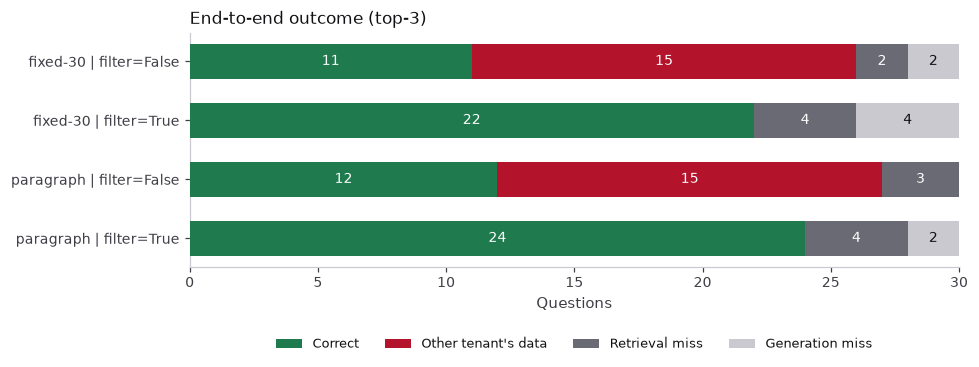

In [12]:
plots.outcomes(results, LANG);

In [13]:
res = results["paragraph | filter=False"]
res[res["outcome"] == "wrong_tenant"][["query_id", "expected", "generated"]].head(3)

,query_id,expected,generated
0,andina-q01,22 business days,"At Boreal Health, every permanent employee gets 18 business days o..."
3,boreal-q02,30 days in advance,Vacation is requested in the portal at least 15 days in advance.
5,boreal-q03,10 unused days,"At year end, a maximum of 5 unused days can be carried over to the..."


In [14]:
res = results["paragraph | filter=True"]
res[res["outcome"] != "correct"][["query_id", "expected", "generated", "retrieved_evidence"]]

,query_id,expected,generated,retrieved_evidence
6,andina-q04,40 USD per travel day,Carried-over days expire on March 31.,False
7,boreal-q04,55 USD per travel day,Carried-over days expire on March 31.,False
12,andina-q07,14 characters,"At Andina Foods, every permanent employee gets 22 business days of...",False
13,boreal-q07,16 characters,"At Boreal Health, every permanent employee gets 18 business days o...",False
20,andina-q11,payment of 300 USD,"At Andina Foods, eligible staff can work remotely up to 3 days per...",True
21,boreal-q11,payment of 450 USD,"At Boreal Health, eligible staff can work remotely up to 2 days pe...",True


End-to-end accuracy alone doesn't tell you what to fix:

- **Without a filter**, half of the answers use the other tenant's data. That's a **retrieval and security** problem: changing the model or the prompt won't fix it.
- **With the filter**, Recall@3 is high, but some answers still fail with the evidence in the context (`retrieved_evidence=True`). There you improve **generation** (prompt or model), not chunking.

## 6. AWS equivalent

| This lab | On AWS | Main differences |
|---|---|---|
| `chunking.py` | Bedrock Knowledge Bases chunking: default (~300 tokens), fixed-size with overlap, hierarchical, semantic, or no chunking | Bedrock counts tokens, not words, and semantic chunking uses a foundation model at extra cost. |
| `retrieval.py` (TF-IDF) | Embeddings model + vector store; semantic or hybrid search | Embeddings capture synonyms that TF-IDF misses. |
| `Retriever.search(tenant=...)` | `equals` metadata filter on `Retrieve` / `RetrieveAndGenerate`, with attributes from `.metadata.json` | Bedrock supports more operators (`in`, `greaterThan`, `andAll`, `orAll`…). |
| `evaluation.retrieval_metrics` | Bedrock RAG evaluation, *Retrieve only* job: *context relevance* and *context coverage* | Bedrock uses an LLM as a judge and doesn't need chunk IDs; *context coverage* requires ground truth. Here the metrics are deterministic. |
| `evaluation.end_to_end` | Bedrock RAG evaluation, *Retrieve and generate* job: *correctness*, *faithfulness*, *citation precision*… | Bedrock can also evaluate an external RAG if you bring its responses. |

### Try this

- Before section 2, add `chunking.STRATEGIES["fixed-30-ov10"] = lambda d: chunking.fixed(d, 30, overlap=10)` and compare Recall@1.
- Remove the filter for one tenant only and count how many answers leak data.
- Rephrase a question with synonyms and watch recall drop with TF-IDF.